#Module 12 Project 4 Jerome Kaczmarek

##Part 1: Data Preparation

###Import necessary python packages and main datafile:



In [192]:
#import necessary python packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

In [193]:
df = pd.read_csv('EcommerceData.csv', encoding='ISO-8859-1')

###Data inspection and cleaning:

In [194]:
#Obtain df file info for feature and datatype info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [195]:
#inspect features and how values are listed
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [196]:
#show missing values by feature
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [197]:
# Drop rows where the 'Description' column is missing a value
df.dropna(subset=['Description'], inplace=True)
print(f"Missing values remaining in Description: {df['Description'].isnull().sum()}")
print(f"New dataset shape: {df.shape}")

Missing values remaining in Description: 0
New dataset shape: (540455, 8)


###Missing valudes dropped in Description feature as the total missing value sum was a significantly low percentage compared to the overall total.
###CustomerID missing values were not dropped as they are a much larger portion of overall CustomerID total sum and may represent non-repetitive customers or one-off purchases.

In [198]:
# find total number of duplicate rows
df.duplicated().sum()

np.int64(5268)

In [199]:
# Drop duplicate rows
df.drop_duplicates(inplace=True)
print(f"Dataset shape after removing duplicates: {df.shape}")

Dataset shape after removing duplicates: (535187, 8)


###Duplicate rows represent less than 1% of total count, rows dropped

In [200]:
# Show the count of unique values for each feature
df.nunique()

,0
InvoiceNo,24446
StockCode,3958
Description,4223
Quantity,671
InvoiceDate,22309
UnitPrice,1630
CustomerID,4372
Country,38


In [201]:
# Show the value range and statistical summary for UnitPrice
display(df['UnitPrice'].describe())

,UnitPrice
count,535187.000000
mean,4.645242
std,97.364810
min,-11062.060000
25%,1.250000
50%,2.080000
75%,4.130000
max,38970.000000


In [202]:
# Count the number of instances with a UnitPrice of $0 or below
zero_or_below_count = (df['UnitPrice'] <= 0).sum()
print(f"Total count of instances with a UnitPrice of $0 or below: {zero_or_below_count}")

Total count of instances with a UnitPrice of $0 or below: 1058


In [203]:
# Drop rows where UnitPrice is less than or equal to 0
df = df[df['UnitPrice'] > 0]

# Confirm that zero and negative prices have been removed
print(f"New dataset shape: {df.shape}")
print(f"Remaining rows count: {len(df)}")

New dataset shape: (534129, 8)
Remaining rows count: 534129


In [204]:
# Calculate and print the count of rows where UnitPrice is strictly below $0
negative_prices_count = (df['UnitPrice'] < 0).sum()
print(f"Amount of UnitPrice values strictly below $0: {negative_prices_count}")

Amount of UnitPrice values strictly below $0: 0


In [205]:
# Recalculate summary statistics for UnitPrice after data cleaning
display(df['UnitPrice'].describe())

,UnitPrice
count,534129.000000
mean,4.695864
std,95.079189
min,0.001000
25%,1.250000
50%,2.100000
75%,4.130000
max,38970.000000


###Dropped any instances that had an observed UnitPrice of $0 or below

In [206]:
# Show the value range and statistical summary for Quantity
display(df['Quantity'].describe())

,Quantity
count,534129.000000
mean,9.916818
std,216.452113
min,-80995.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,80995.000000


In [207]:
# Count the number of values in the 'Quantity' column that are 0 or below
quantity_zero_or_below = (df['Quantity'] <= 0).sum()
print(f"Number of values in Quantity that are 0 or below: {quantity_zero_or_below}")

Number of values in Quantity that are 0 or below: 9251


In [208]:
# Drop rows where Quantity is less than or equal to 0
df = df[df['Quantity'] > 0]

# Display the new shape and descriptive statistics of Quantity to verify
print(f"New dataset shape: {df.shape}")
display(df['Quantity'].describe())

New dataset shape: (524878, 8)


,Quantity
count,524878.000000
mean,10.616600
std,156.280031
min,1.000000
25%,1.000000
50%,4.000000
75%,11.000000
max,80995.000000


###Due to values present in the Quantity feature being 0 or below, dropped those values for consistency of analysis

In [209]:
# Convert InvoiceDate to datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Verify the change
print(df['InvoiceDate'].dtypes)
print(df[['InvoiceDate']].head())

datetime64[ns]
          InvoiceDate
0 2010-12-01 08:26:00
1 2010-12-01 08:26:00
2 2010-12-01 08:26:00
3 2010-12-01 08:26:00
4 2010-12-01 08:26:00


###Changed the format of the feature 'InvoiceDate' to datetime

##Part 2 Feature Engineering

###Create new feature called 'TotalPrice' that is compiled by multiplying the 'Quantity' by the 'UnitPrice' of each instance:

In [210]:
# Create the 'TotalPrice' feature by multiplying 'Quantity' and 'UnitPrice'
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Display the first few rows to verify the new feature
df[['Quantity', 'UnitPrice', 'TotalPrice']].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


###Create time feature that extracts the hour within the date time of each instance:

In [211]:
# Create the 'Hour' feature by extracting the hour from 'InvoiceDate'
df['Hour'] = df['InvoiceDate'].dt.hour

# Display a preview of the InvoiceDate and the new Hour feature
df[['InvoiceDate', 'Hour']].head()

,InvoiceDate,Hour
0,2010-12-01 08:26:00,8
1,2010-12-01 08:26:00,8
2,2010-12-01 08:26:00,8
3,2010-12-01 08:26:00,8
4,2010-12-01 08:26:00,8


In [212]:
# List all of the unique values in the 'Hour' feature to verify 24 hour integrity
unique_hours = sorted(df['Hour'].unique())
print("Unique hours in the dataset:", unique_hours)

Unique hours in the dataset: [np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20)]


###Create new feature that extracts the day of the week from each instance :

In [213]:
# Extract the day of the week for each instance and name the feature 'DayofWeek'
df['DayofWeek'] = df['InvoiceDate'].dt.day_name()

# Display a preview of the dataset with the new feature
df[['InvoiceDate', 'DayofWeek']].head()

,InvoiceDate,DayofWeek
0,2010-12-01 08:26:00,Wednesday
1,2010-12-01 08:26:00,Wednesday
2,2010-12-01 08:26:00,Wednesday
3,2010-12-01 08:26:00,Wednesday
4,2010-12-01 08:26:00,Wednesday


In [214]:
# list all unique values in the 'DayofWeek' feature to verify
unique_days = df['DayofWeek'].unique()
print("Unique days of the week in the dataset:", unique_days)

Unique days of the week in the dataset: ['Wednesday' 'Thursday' 'Friday' 'Sunday' 'Monday' 'Tuesday']


In [215]:
# Extract the calendar month from 'InvoiceDate' and label it 'Month'
df['Month'] = df['InvoiceDate'].dt.month_name()

# Display the first few rows of InvoiceDate and the new Month column
df[['InvoiceDate', 'Month']].head()

,InvoiceDate,Month
0,2010-12-01 08:26:00,December
1,2010-12-01 08:26:00,December
2,2010-12-01 08:26:00,December
3,2010-12-01 08:26:00,December
4,2010-12-01 08:26:00,December


In [216]:
# List all unique values in the 'Month' feature to verify
unique_months = df['Month'].unique()
print("Unique months in the dataset:", unique_months)

Unique months in the dataset: ['December' 'January' 'February' 'March' 'April' 'May' 'June' 'July'
 'August' 'September' 'October' 'November']


In [217]:
# Show all unique values in the 'Country' feature, sorted alphabetically
unique_countries = sorted(df['Country'].unique())
print(f"Unique countries ({len(unique_countries)} total):")
for country in unique_countries:
    print(country)

Unique countries (38 total):
Australia
Austria
Bahrain
Belgium
Brazil
Canada
Channel Islands
Cyprus
Czech Republic
Denmark
EIRE
European Community
Finland
France
Germany
Greece
Hong Kong
Iceland
Israel
Italy
Japan
Lebanon
Lithuania
Malta
Netherlands
Norway
Poland
Portugal
RSA
Saudi Arabia
Singapore
Spain
Sweden
Switzerland
USA
United Arab Emirates
United Kingdom
Unspecified


In [218]:
# Map specific country names to their standard full names
country_mapping = {
    'EIRE': 'Ireland',
    'RSA': 'Republic of South Africa '
}

# Replace the values in the Country column
df['Country'] = df['Country'].replace(country_mapping)

In [219]:
# Show all unique values in the 'Country' feature, sorted alphabetically
unique_countries_updated = sorted(df['Country'].unique())
print(f"Unique countries ({len(unique_countries_updated)} total):")
for country in unique_countries_updated:
    print(country)

Unique countries (38 total):
Australia
Austria
Bahrain
Belgium
Brazil
Canada
Channel Islands
Cyprus
Czech Republic
Denmark
European Community
Finland
France
Germany
Greece
Hong Kong
Iceland
Ireland
Israel
Italy
Japan
Lebanon
Lithuania
Malta
Netherlands
Norway
Poland
Portugal
Republic of South Africa 
Saudi Arabia
Singapore
Spain
Sweden
Switzerland
USA
United Arab Emirates
United Kingdom
Unspecified


###For readability in downstream analysis, changed Country "EIRE" to "Ireland" and "RSA" to "Republic of South Africa"

##Part 3 Exploratory Data Analysis

###Calculate total number of customers:

In [220]:
# Calculate the total number of CustomerID values
total_customer_ids = df['CustomerID'].count()
print("Total CustomerID values:", total_customer_ids)

# Calculate the total number of unique CustomerID values
unique_customer_ids = df['CustomerID'].nunique()
print("Total unique CustomerID values (excluding null-values):", unique_customer_ids)

Total CustomerID values: 392692
Total unique CustomerID values (excluding null-values): 4338


###Total number of actual customers: 4,338

###Calculate total number of transactions:

In [221]:
# Calculate the total amount of instances with a value in 'InvoiceNo'
total_invoice_instances = df['InvoiceNo'].count()
print("Total number of transactions:", total_invoice_instances)

Total number of transactions: 524878


###Total number of individual transactions: 524,878

###Calculate Total Revenue:

In [222]:
# Calculate the total sum of the 'TotalPrice' feature
total_revenue = df['TotalPrice'].sum()
print("Total revenue (sum of TotalPrice):", total_revenue)

Total revenue (sum of TotalPrice): 10642110.804000001


In [223]:
# Format the total revenue to currency with $ and with only 2 decimal places
formatted_revenue = f"${total_revenue:,.2f}"
print("Total revenue:", formatted_revenue)

Total revenue: $10,642,110.80


###Total Revenue: $10,642,110.80

###Calculate average order value :

In [224]:
# Calculate the average order value
average_order_value = total_revenue / total_invoice_instances
print(f"Average Order Value: ${average_order_value:.2f}")

Average Order Value: $20.28


###The average order value is $20.28

##Part 4 Advanced Visualizations

###Create heatmap showing sales volume by hour and day of week:

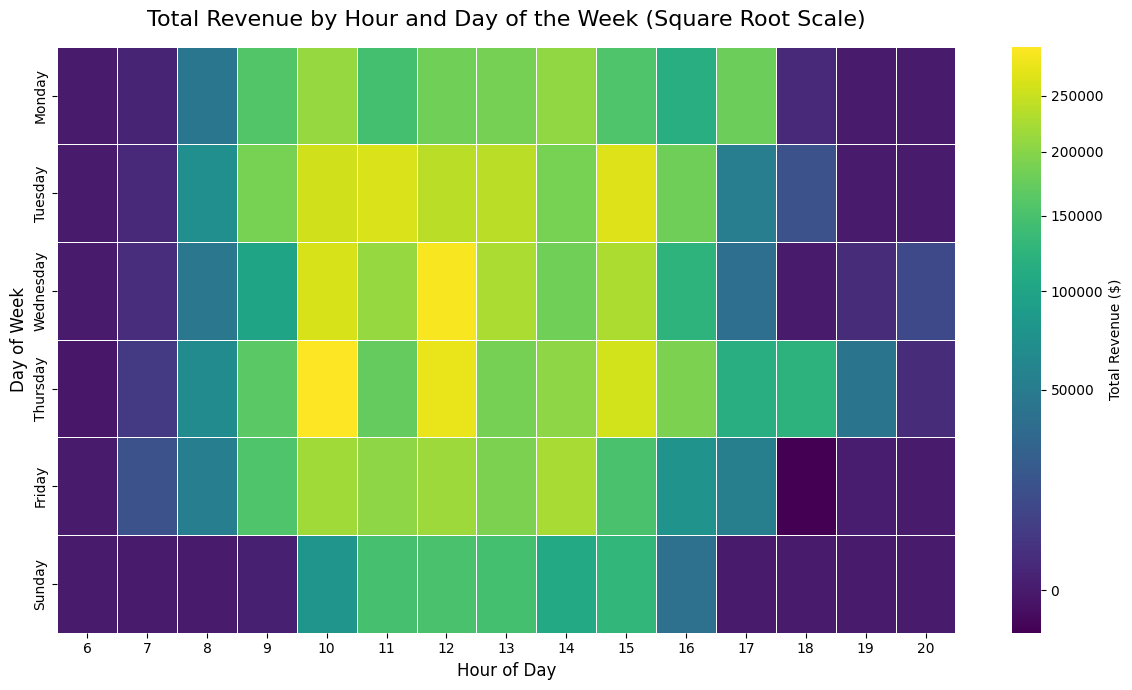

In [225]:
import matplotlib.colors as mcolors

# Plot the heatmap using a square root scale for color normalization
plt.figure(figsize=(12, 7))
sns.heatmap(
    heatmap_data,
    cmap='viridis',
    norm=mcolors.PowerNorm(gamma=0.5),
    annot=False,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={'label': 'Total Revenue ($)'}
)

plt.title('Total Revenue by Hour and Day of the Week (Square Root Scale)', fontsize=16, pad=15)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.tight_layout()

# Save the figure as a PNG file
plt.savefig('heatmap_revenue_by_hour.png', dpi=300, bbox_inches='tight')
plt.show()

###The heatmap above reflects the total sales by the hour that utilizes a color-blind color palette along with converting the revenue distribution to a square root scale to more easily determine minor sales fluctuations throughout the day.

###Create a density plot (KDE) comparing order values (weekday vs. weekend):

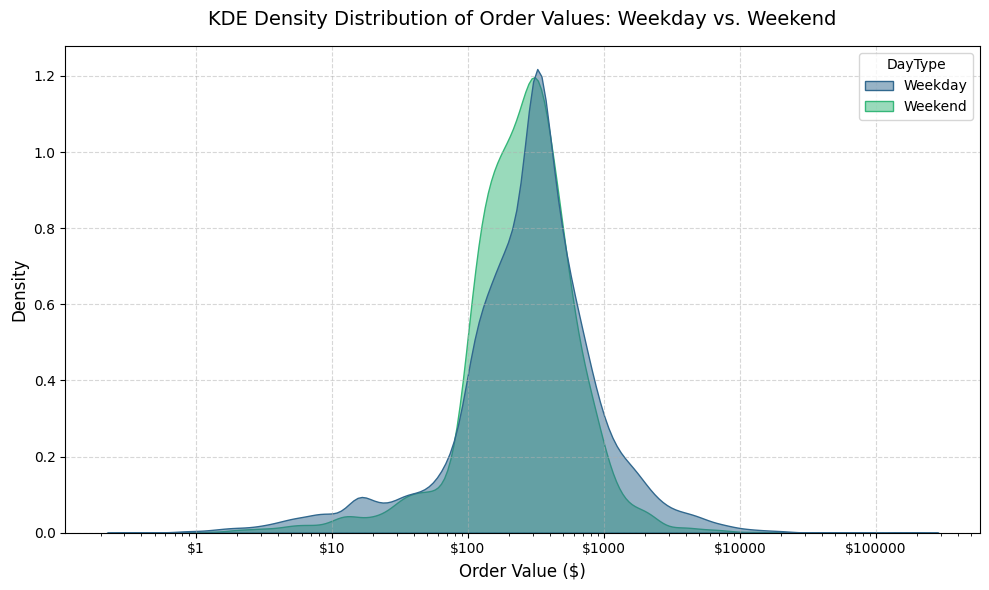

In [226]:
# Create the KDE density plot comparing weekday vs weekend order values
plt.figure(figsize=(10, 6))
ax = sns.kdeplot(
    data=order_values,
    x='TotalPrice',
    hue='DayType',
    common_norm=False,
    log_scale=True,
    fill=True,
    palette='viridis',
    alpha=0.5
)

# Set the x-axis formatter to show actual decimal values instead of scientific/log notation
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('$%g'))

plt.title('KDE Density Distribution of Order Values: Weekday vs. Weekend', fontsize=14, pad=15)
plt.xlabel('Order Value ($)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the plot as a PNG image file
plt.savefig('density_order_values_weekday_vs_weekend.png', dpi=300, bbox_inches='tight')
plt.show()

###The above KDE density plot visualizes the concentrations of the order values reflected across the distribution of the order value range.
###This allows the viewer to see that the weekday values tail off to the right in a much stronger density as compared to the weekend days.

###Create a pair plot to examine relationships between multiple numerical variables:

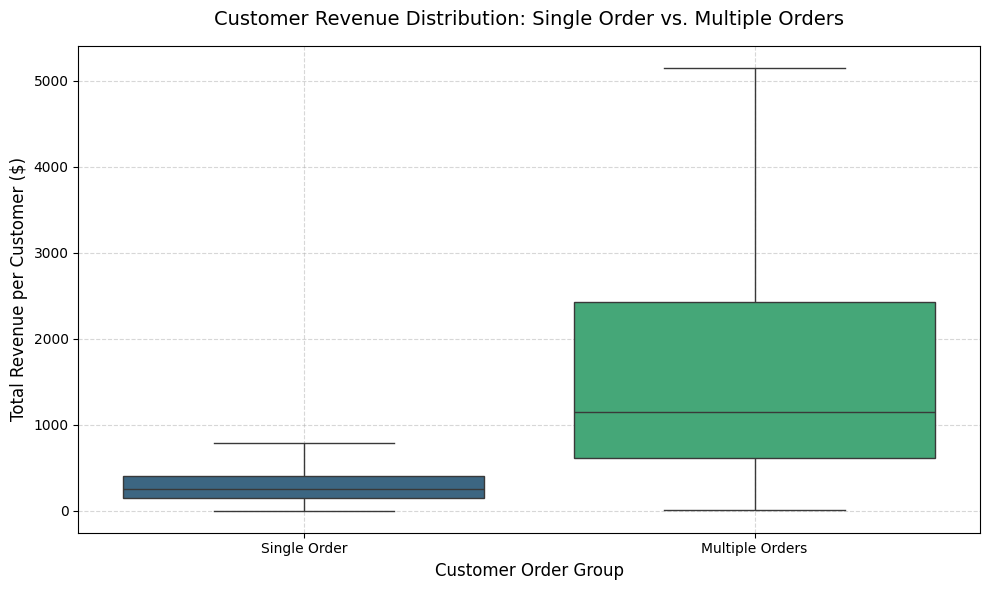

                  count         mean           std   min     25%      50%  \
OrderGroup                                                                  
Multiple Orders  2845.0  2907.985706  10899.538240  6.90  614.66  1154.47   
Single Order     1493.0   411.245520   2034.246264  3.75  152.65   255.91   

                     75%        max  
OrderGroup                           
Multiple Orders  2429.83  280206.02  
Single Order      406.09   77183.60  


<Figure size 640x480 with 0 Axes>

In [227]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Group data by CustomerID to get order counts (unique InvoiceNo) and total revenue per customer
# Filter out rows where CustomerID is null to focus on identified customer behavior
customer_data = df[df['CustomerID'].notnull()].groupby('CustomerID').agg(
    NumOrders=('InvoiceNo', 'nunique'),
    TotalRevenue=('TotalPrice', 'sum')
).reset_index()

# Classify customers into 'Single Order' vs 'Multiple Orders'
customer_data['OrderGroup'] = np.where(customer_data['NumOrders'] == 1, 'Single Order', 'Multiple Orders')

# Create the Box Plot with updated arguments to avoid future warnings
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=customer_data,
    x='OrderGroup',
    y='TotalRevenue',
    hue='OrderGroup',
    legend=False,
    palette='viridis',
    showfliers=False # Hide extreme outliers to keep the distribution clear and comparable
)

plt.title('Customer Revenue Distribution: Single Order vs. Multiple Orders', fontsize=14, pad=15)
plt.xlabel('Customer Order Group', fontsize=12)
plt.ylabel('Total Revenue per Customer ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the plot as a PNG image file
plt.savefig('revenue_single_vs_multiple_orders.png', dpi=300, bbox_inches='tight')
plt.show()

# Output summary statistics for validation
summary_stats = customer_data.groupby('OrderGroup')['TotalRevenue'].describe()
print(summary_stats)

# Save the plot as a PNG image file
plt.savefig('customer_revenue_distribution_single_vs_multiple_orders.png', dpi=300, bbox_inches='tight')
plt.show()

###The above boxplot shows the statistical difference in avearge reveune generated by single order customers per order vs customers who order multiple orders.
###This shows that repeat customers create much more revenue by average on each order than customers who order once.

###Create a boxplot to compare distributions (e.g., order values by country or time period):

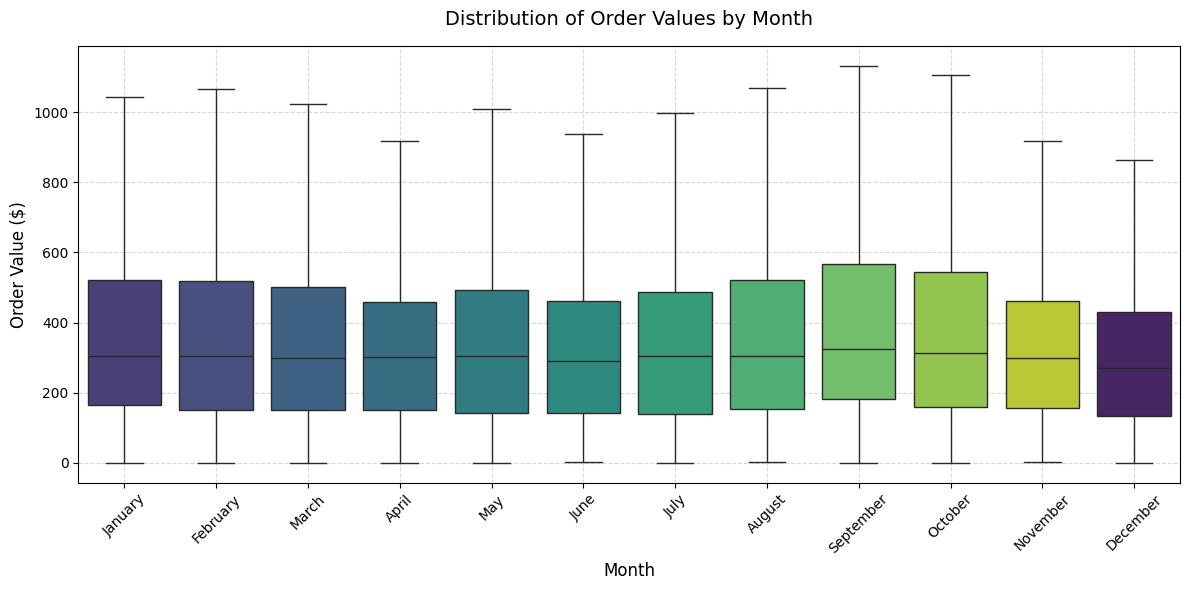

In [228]:
# Group by InvoiceNo and Month to get the total order value for each transaction
order_values_by_month = df.groupby(['InvoiceNo', 'Month'])['TotalPrice'].sum().reset_index()

# Define the chronological order of months
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

# Create the boxplot with a log scale to handle highly skewed order values
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=order_values_by_month,
    x='Month',
    y='TotalPrice',
    order=month_order,
    hue='Month',
    legend=False,
    palette='viridis',
    showfliers=False # Hiding extreme outliers to better visualize the main distributions
)

plt.title('Distribution of Order Values by Month', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Order Value ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the plot as a PNG image file
plt.savefig('order_values_distribution_by_month.png', dpi=300, bbox_inches='tight')
plt.show()

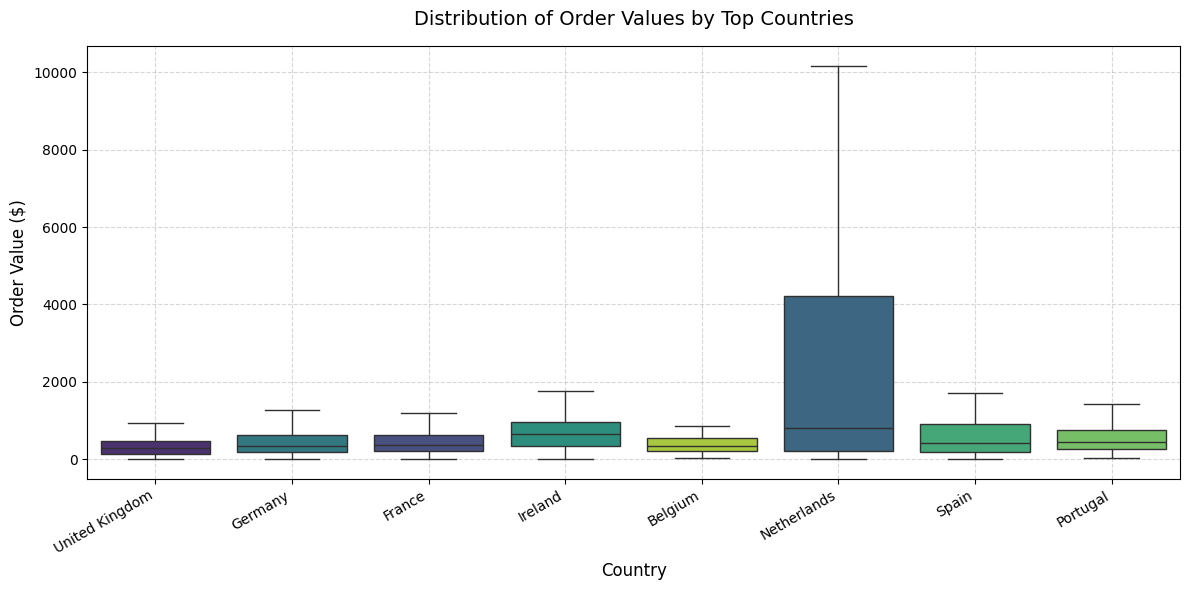

In [229]:
# Calculate total order value per invoice
order_values_by_country = df.groupby(['InvoiceNo', 'Country'])['TotalPrice'].sum().reset_index()

# Identify the top 8 countries by total number of orders to ensure a clean visualization
top_countries = order_values_by_country['Country'].value_counts().nlargest(8).index
filtered_orders = order_values_by_country[order_values_by_country['Country'].isin(top_countries)]

# Create the boxplot comparing order values by country
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=filtered_orders,
    x='Country',
    y='TotalPrice',
    order=top_countries,
    hue='Country',
    legend=False,
    palette='viridis',
    showfliers=False # Hide extreme outliers to visually focus on core distributions
)

plt.title('Distribution of Order Values by Top Countries', fontsize=14, pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Order Value ($)', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the plot as a PNG image file
plt.savefig('order_values_by_country.png', dpi=300, bbox_inches='tight')
plt.show()

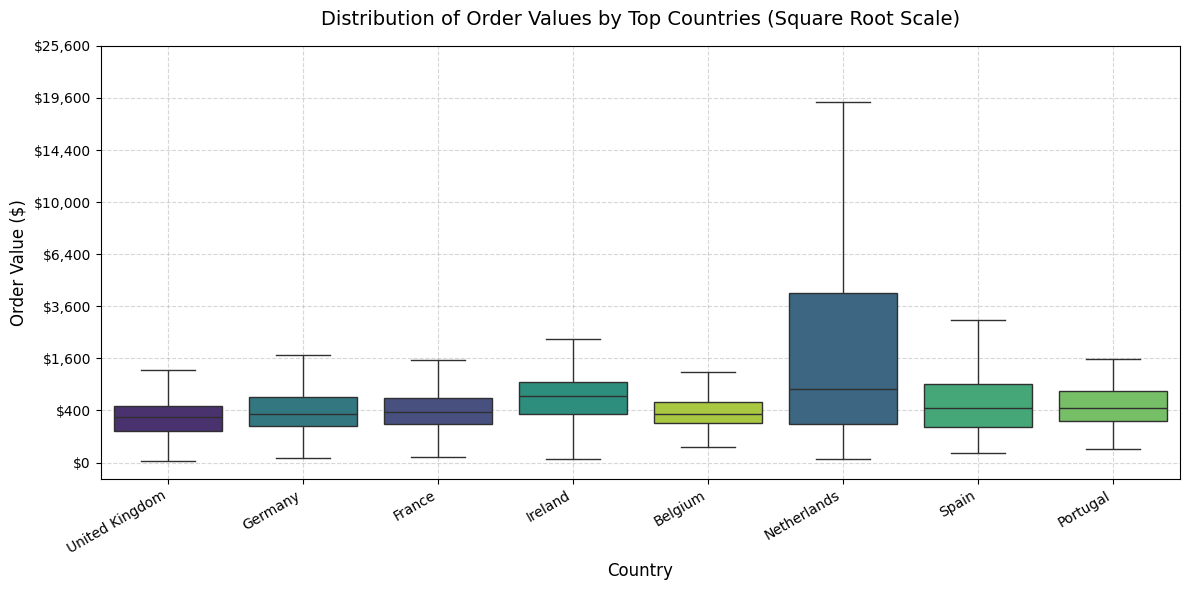

In [230]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Create a copy to avoid SettingWithCopyWarning
filtered_orders_scaled = filtered_orders.copy()
# Calculate the square root of the order value
filtered_orders_scaled['SqrtTotalPrice'] = np.sqrt(filtered_orders_scaled['TotalPrice'])

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=filtered_orders_scaled,
    x='Country',
    y='SqrtTotalPrice',
    order=top_countries,
    hue='Country',
    legend=False,
    palette='viridis',
    showfliers=False  # Hide extreme outliers to visually focus on core distributions
)

# Format the y-axis labels to show original dollar values corresponding to the square root scale
ax = plt.gca()
current_ticks = ax.get_yticks()
# Filter out negative tick values that might appear due to margin padding
valid_ticks = [t for t in current_ticks if t >= 0]
ax.set_yticks(valid_ticks)
ax.set_yticklabels([f"${int(t**2):,}" for t in valid_ticks])

plt.title('Distribution of Order Values by Top Countries (Square Root Scale)', fontsize=14, pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Order Value ($)', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the plot as a PNG image file
plt.savefig('order_values_by_country_sqrt.png', dpi=300, bbox_inches='tight')
plt.show()

###Created boxplot above to reflect distrubution across the top 8 countries and used square root scales to highlight the differences in a visual manner more accurately

###Create a regression plot to explore relationships between variables (e.g., quantity vs. price):

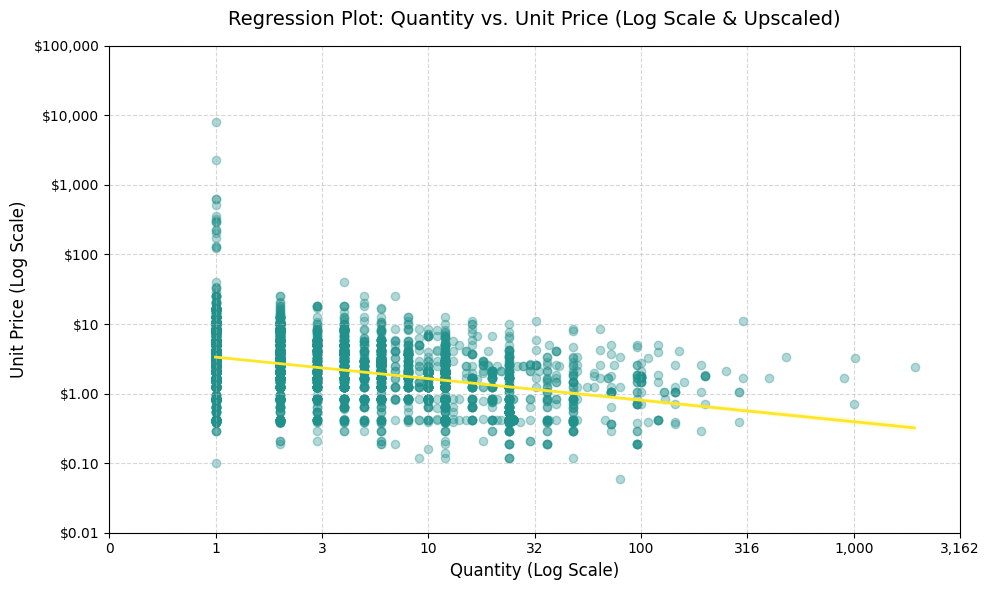

In [238]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Upscale the data sample size to 5,000 points to show density
upscaled_sample = df.sample(n=5000, random_state=42).copy()

# Filter out any non-positive values to safely apply base-10 logarithm
upscaled_sample = upscaled_sample[(upscaled_sample['Quantity'] > 0) & (upscaled_sample['UnitPrice'] > 0)]

# Calculate log10 values for Quantity and UnitPrice
upscaled_sample['LogQuantity'] = np.log10(upscaled_sample['Quantity'])
upscaled_sample['LogUnitPrice'] = np.log10(upscaled_sample['UnitPrice'])

plt.figure(figsize=(10, 6))
sns.regplot(
    data=upscaled_sample,
    x='LogQuantity',
    y='LogUnitPrice',
    scatter_kws={'alpha': 0.35, 'color': '#21918c'},
    line_kws={'color': '#fde725', 'linewidth': 2}
)

# Format the axis labels with original values using 10^x formatting
ax = plt.gca()

# Format X axis - converting all calculated values
x_ticks = ax.get_xticks()
ax.set_xticks(x_ticks)
ax.set_xticklabels([f"{int(round(10**x)):,}" for x in x_ticks])

# Format Y axis
y_ticks = ax.get_yticks()
ax.set_yticks(y_ticks)
ax.set_yticklabels([f"${10**y:.2f}" if y < 1 else f"${int(10**y):,}" for y in y_ticks])

plt.title('Regression Plot: Quantity vs. Unit Price (Log Scale & Upscaled)', fontsize=14, pad=15)
plt.xlabel('Quantity (Log Scale)', fontsize=12)
plt.ylabel('Unit Price (Log Scale)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the log-log plot as a PNG file
plt.savefig('regression_quantity_vs_unitprice_log.png', dpi=300, bbox_inches='tight')
plt.show()

###The regression plot above was upscaled and used a log scale to more accurately visualize the distribution change in pricing as we scale up the quantity scale.
###Prior to upsizing and converting to a log scale, the plots were too densely packed showing barely any movement until the exterme highs of the quantity scale.

##Part 5 Geospatial Analysis

###Aggregate the invoices by country

In [249]:
# Aggregate total line-item transactions and unique invoices by country
country_counts = df.groupby('Country').agg(
    TotalItemTransactions=('InvoiceNo', 'count'),
    UniqueInvoices=('InvoiceNo', 'nunique')
).reset_index()

# Sort the values to view the countries with the highest sales frequency
country_counts_sorted = country_counts.sort_values(by='UniqueInvoices', ascending=False).reset_index(drop=True)

# Display the aggregated data table
display(country_counts_sorted)

,Country,TotalItemTransactions,UniqueInvoices
0,United Kingdom,479985,18019
1,Germany,9025,457
2,France,8392,392
3,Ireland,7879,288
4,Belgium,2031,98
5,Netherlands,2359,94
6,Spain,2479,90
7,Portugal,1492,58
8,Australia,1181,57
9,Switzerland,1958,54


###Using urlib.request, access url to download world map dataset zip file

In [251]:
import urllib.request
import os

# Define target URL and destination filename
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
output_zip = "ne_110m_admin_0_countries.zip"

try:
    print("Starting download...")
    urllib.request.urlretrieve(url, output_zip)
    print(f"Successfully downloaded {output_zip}!")
except Exception as e:
    print(f"Error downloading map file: {e}")

Starting download...
Successfully downloaded ne_110m_admin_0_countries.zip!


###Using zipfile, Unzip world map dataset file and merge aggregated data on invoices by country

In [257]:
import zipfile
# 1. Unzip the downloaded Natural Earth shapefile package
zip_path = "ne_110m_admin_0_countries.zip"
extract_dir = "ne_110m_admin_0_countries"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# 2. Find and load the main shapefile (.shp)
shp_file = [os.path.join(extract_dir, f) for f in os.listdir(extract_dir) if f.endswith('.shp')][0]
world = gpd.read_file(shp_file)

# 3. Align country names to match Natural Earth specifications
country_name_alignment = {
    'United Kingdom': 'United Kingdom',
    'USA': 'United States of America',
    'Republic of South Africa ': 'South Africa',
    'Hong Kong': 'China',
    'Singapore': 'Singapore'
}
country_counts_sorted['Country_Cleaned'] = country_counts_sorted['Country'].replace(country_name_alignment)

# 4. Merge our aggregated invoice data with the real-world map dataset
world_merged = world.merge(country_counts_sorted, left_on='SOVEREIGNT', right_on='Country_Cleaned', how='left')

# Fill NaN values with 0 for countries with no matching invoice records
world_merged['TotalItemTransactions'] = world_merged['TotalItemTransactions'].fillna(0)
world_merged['UniqueInvoices'] = world_merged['UniqueInvoices'].fillna(0)

# Display the top countries in the merged spatial dataset to verify alignment
display(world_merged[['SOVEREIGNT', 'TotalItemTransactions', 'UniqueInvoices']].sort_values(by='UniqueInvoices', ascending=False).head(10))

,SOVEREIGNT,TotalItemTransactions,UniqueInvoices
20,United Kingdom,479985.0,18019.0
143,United Kingdom,479985.0,18019.0
121,Germany,9025.0,457.0
23,France,8392.0,392.0
43,France,8392.0,392.0
134,France,8392.0,392.0
133,Ireland,7879.0,288.0
129,Belgium,2031.0,98.0
130,Netherlands,2359.0,94.0
132,Spain,2479.0,90.0


###Create choropleth map to visualize number of invoices by country

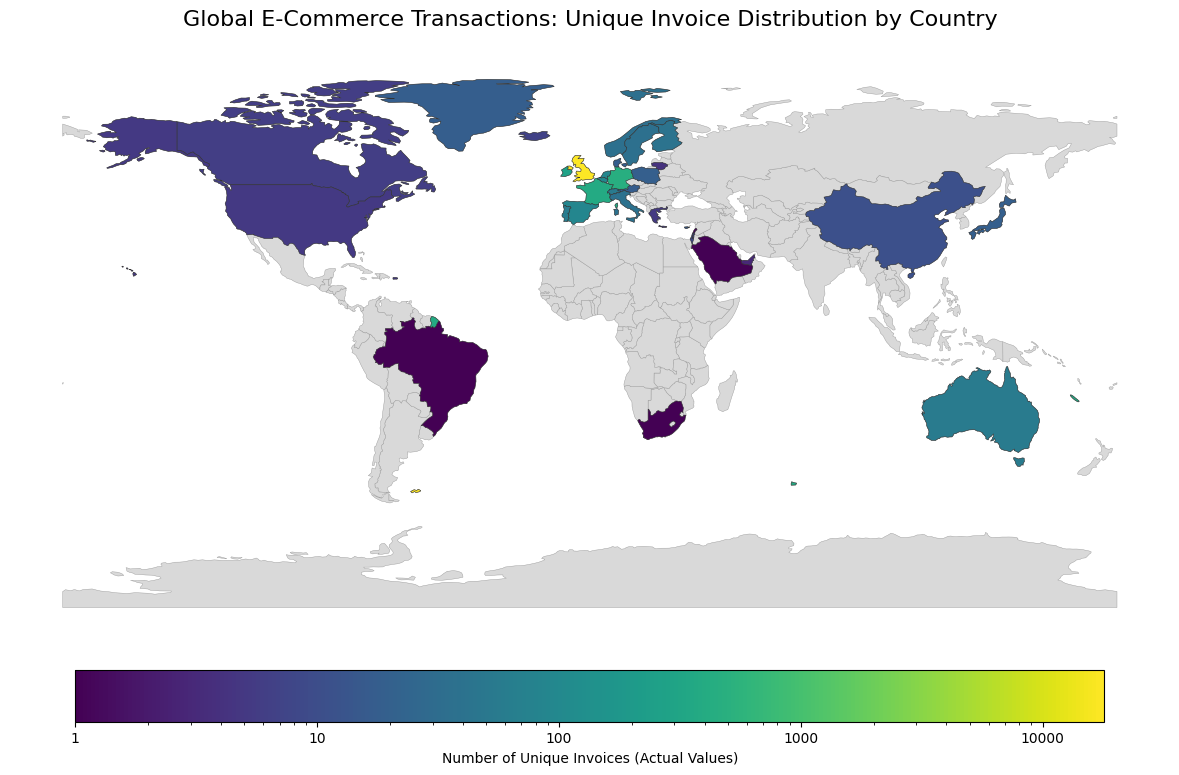

In [256]:
# Create global choropleth map
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

# Set a clean background representation for oceans
ax.set_facecolor('#f4f4f4')

# Define logarithmic scale normalization to deal with the heavy skew of UK orders
norm = colors.LogNorm(vmin=1, vmax=world_merged['UniqueInvoices'].max())

# Plot the base map with empty values colored in light gray
world_merged.plot(
    ax=ax,
    color='#d9d9d9',
    edgecolor='#999999',
    linewidth=0.3
)

# Plot the aggregated invoice distribution
world_merged[world_merged['UniqueInvoices'] > 0].plot(
    column='UniqueInvoices',
    ax=ax,
    legend=True,
    cmap='viridis',
    norm=norm,
    edgecolor='#333333',
    linewidth=0.4,
    legend_kwds={
        'label': "Number of Unique Invoices (Actual Values)",
        'orientation': "horizontal",
        'pad': 0.05,
        'shrink': 0.7,
        'ticks': [1, 10, 100, 1000, 10000],
        'format': '%g'
    }
)

# Set map titles and adjust layout dimensions
plt.title('Global E-Commerce Transactions: Unique Invoice Distribution by Country', fontsize=16, pad=20)
ax.set_axis_off()
plt.tight_layout()

# Save the map visualization
plt.savefig('ecommerce_global_transactions_map.png', dpi=300, bbox_inches='tight')
plt.show()

###Map analysis: The highest concentration of invoices is coming out of the UK and surrounding European Union nations with Australia being the closest in volume of invoices that is located outside of the EU.